# Análise exploratória: fraude em cartão de crédito

Preencha com as conclusões do grupo. Rode da raiz do projeto (`jupyter notebook`).

In [2]:
import sys; sys.path.append('..')
import pandas as pd, matplotlib.pyplot as plt, seaborn as sns, numpy as np
from src.data import load_data

# Configuração do estilo dos gráficos
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

df = load_data('../data/creditcard.csv')
df.shape
print(f"Dimensões do dataset: {df.shape[0]} linhas e {df.shape[1]} colunas.")

Dimensões do dataset: 284807 linhas e 31 colunas.


## 1. Desbalanceamento

Class
0    284315
1       492
Name: count, dtype: int64
Fraudes: 0.1727%


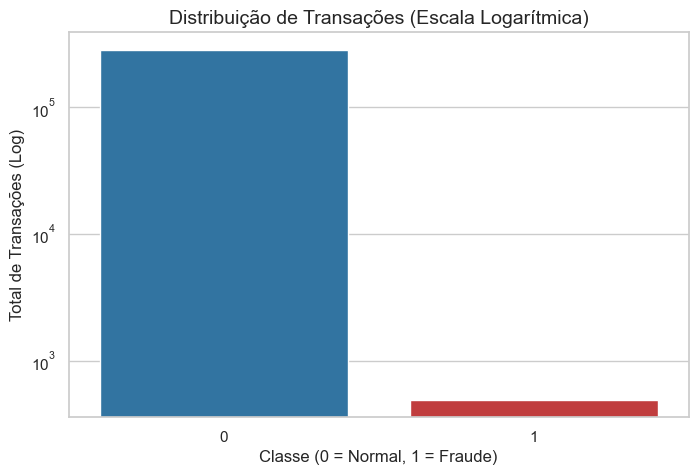

Gráfico 'grafico_desbalanceamento.png' salvo com sucesso na raiz do projeto!


In [3]:
# Exibe a quantidade absoluta de transações de cada classe (0 = Normal, 1 = Fraude)
print(df['Class'].value_counts())
# Como as classes são 0 e 1, a média (mean) representa exatamente a proporção de fraudes (1).
print(f"Fraudes: {df['Class'].mean():.4%}")

# Criamos a figura
plt.figure(figsize=(8, 5))

# Plotamos o gráfico (Azul para Normal, Vermelho para Fraude)
ax = sns.countplot(x='Class', hue='Class',data=df, palette=['#1f77b4', '#d62728'], legend=False)
plt.yscale('log') 

# Definição dos parâmetros do gráfico
plt.title('Distribuição de Transações (Escala Logarítmica)', fontsize=14)
plt.xlabel('Classe (0 = Normal, 1 = Fraude)')
plt.ylabel('Total de Transações (Log)')

# Salva o gráfico em alta resolução
plt.savefig('../grafico_desbalanceamento.png', dpi=300, bbox_inches='tight')

plt.show()
print("Gráfico 'grafico_desbalanceamento.png' salvo com sucesso na raiz do projeto!")

## 2. Completude e tipos

_Há valores faltantes? Quais os tipos?_

In [6]:
# Completude: Calcula o total geral de valores faltantes (nulos/NaN) no dataset inteiro.
# O primeiro .sum() soma os nulos por coluna, o segundo .sum() soma o total de todas as colunas.
total_nulos = df.isna().sum().sum()
print(f"Total de valores faltantes (nulos) no dataset: {total_nulos}")

print("-" * 45)

# Contagem de quantas colunas existem de cada tipo (int, float, object/texto, etc.)
print("Tipos de dados das colunas:")
print(df.dtypes.value_counts())
print("-" * 45)

# 3. Mini-conclusão para Análise de Pré-processamento (EDA) do dataset.
print("Conclusão para o Pré-processamento:")
if total_nulos == 0:
    print("- A base está perfeitamente preenchida. Não será necessário preencher os valores em branco.")
else:
    print(f"- ATENÇÃO: A base possui {total_nulos} valores em branco. Será necessário aplicar técnicas de imputação (como média, mediana ou KNN Imputer) ou remover as linhas.")

# Verificando se há colunas de texto/objeto
if 'object' in df.dtypes.values:
    print("- ATENÇÃO: Há variáveis categóricas na base. Será necessário aplicar One-Hot Encoding ou Label Encoding antes da modelagem.")
else:
    print("- Como todos os dados já são numéricos (float/int), não será necessário transformar textos em números (One-Hot Encoding).")

Total de valores faltantes (nulos) no dataset: 0
---------------------------------------------
Tipos de dados das colunas:
float64    30
int64       1
Name: count, dtype: int64
---------------------------------------------
Conclusão para o Pré-processamento:
- A base está perfeitamente preenchida. Não será necessário preencher os valores em branco.
- Como todos os dados já são numéricos (float/int), não será necessário transformar textos em números (One-Hot Encoding).


## 3. Distribuição de `Amount` e `Time`

_Por que precisamos escalar essas colunas?_

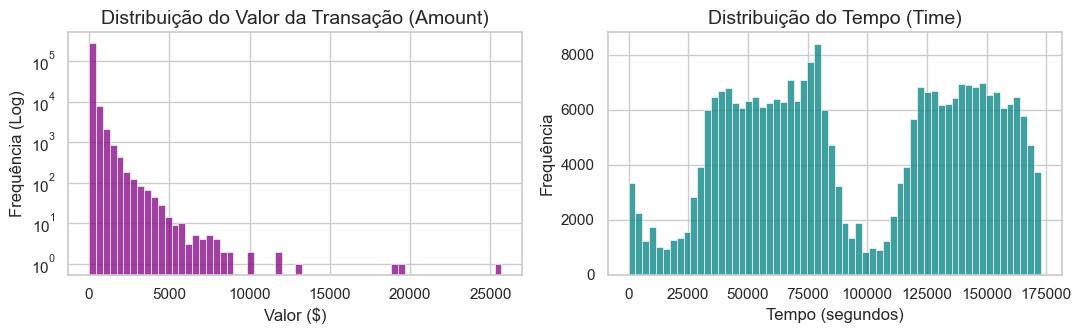

Gráfico duplo 'distribuicao_amount_time.png' salvo com sucesso na raiz do projeto!


In [8]:
# Criando a figura
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))

# 1. Gráfico da Distribuição do Valor (Amount)
sns.histplot(df['Amount'], bins=60, ax=ax[0], color='purple')
ax[0].set_yscale('log') 
ax[0].set_title('Distribuição do Valor da Transação (Amount)', fontsize=14)
ax[0].set_xlabel('Valor ($)')
ax[0].set_ylabel('Frequência (Log)')

# 2. Gráfico da Distribuição do Tempo (Time)
sns.histplot(df['Time'], bins=60, ax=ax[1], color='teal')
ax[1].set_title('Distribuição do Tempo (Time)', fontsize=14)
ax[1].set_xlabel('Tempo (segundos)')
ax[1].set_ylabel('Frequência')

# Gerando o gráfico duplo
plt.tight_layout()
plt.savefig('../distribuicao_amount_time.png', dpi=300, bbox_inches='tight')
plt.show()
print("Gráfico duplo 'distribuicao_amount_time.png' salvo com sucesso na raiz do projeto!")

## 4. Atributos mais relacionados com fraude

Top 10 atributos mais correlacionados com a ocorrência de Fraudes:
V17   -0.326481
V14   -0.302544
V12   -0.260593
V10   -0.216883
V16   -0.196539
V3    -0.192961
V7    -0.187257
V11    0.154876
V4     0.133447
V18   -0.111485
Name: Class, dtype: float64
---------------------------------------------


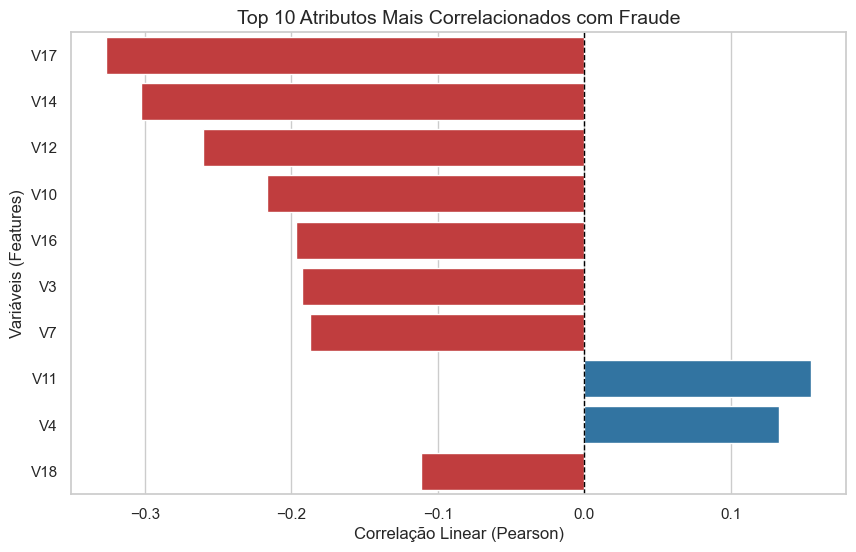

Gráfico 'top10_correlacao_fraude.png' salvo com sucesso na raiz do projeto!


In [10]:
# Cálculos de Correlação
correlacoes = df.corr()['Class'].drop('Class')
top_10 = correlacoes.sort_values(key=abs, ascending=False).head(10)

print("Top 10 atributos mais correlacionados com a ocorrência de Fraudes:")
print(top_10)
print("-" * 45)

# Gráfico de Barras Horizontal
plt.figure(figsize=(10, 6))

# Definindo as cores: Vermelho se a correlação for negativa, Azul se for positiva
cores = ['#d62728' if valor < 0 else '#1f77b4' for valor in top_10.values]
sns.barplot(x=top_10.values, y=top_10.index, hue=top_10.index, palette=cores, legend=False)

# Definição dos parâmetros do gráfico
plt.title('Top 10 Atributos Mais Correlacionados com Fraude', fontsize=14)
plt.xlabel('Correlação Linear (Pearson)')
plt.ylabel('Variáveis (Features)')
plt.axvline(x=0, color='black', linestyle='--', linewidth=1)

# Gerando o gráfico de correlação
plt.savefig('../top10_correlacao_fraude.png', dpi=300, bbox_inches='tight')
plt.show()

print("Gráfico 'top10_correlacao_fraude.png' salvo com sucesso na raiz do projeto!")

## Conclusões

* **Desbalanceamento:** O cenário é o clássico de fraudes. Temos 284.315 transações legítimas e apenas 492 fraudes (0,17%).
* **Base Limpa:** O dataset não tem nenhum valor nulo e já é 100% numérico. 
* **Ajuste de Escala:** Observamos que as colunas `Time` e `Amount` têm escalas muito diferentes das demais. Para o modelo não dar peso errado a elas, teremos que usar um escalonador.
* **Variáveis-Chave:** As features `V17`, `V14` e `V12` têm uma correlação negativa com as fraudes, enquanto `V11` e `V4` puxam a correlação para o lado positivo. Esses serão os atributos que mais ajudarão o modelo no treinamento, por meio destes padrões matemáticos.